In [25]:
# !pip install -U bitsandbytes>=0.46.1

In [1]:
import pandas as pd
import os
import string
import re
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, fisher_exact
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.multitest import multipletests
from transformers import AutoTokenizer, AutoModel
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
WORK_DIR = '/content/drive/My Drive/LDQAV project'

# Russian polarity particles in the feature model: a computational study of *da*, *net*, *aga* and *nea*
Anastasia Dobrynina
***
The project asks which features of the feature model (Roelofsen & Farkas 2015; Farkas & Roelofsen 2019) Russian response particles realize.

We test the existing classification on corpus data and extend it to two colloquial particles that have not been analyzed in this framework, *aga* and *nea*.

Hypotheses:
* **H1**: *net* and *nea* behave alike. Both occur in [reverse,−], [agree,−] and [reverse,+] answers, i.e. both realize either [−] or [reverse].
* **H2**: *da* is restricted to [agree] answers and has no [reverse,+] readings:

  — Masha ne prishla? 'Masha didn't come?'
  — \*Da, prishla. 'Yes, she did.'

* **H3**: *aga* patterns with *da* in [agree,+] answers, but thanks to its [+] feature it can also occur in sarcastic [reverse,+] answers:

  — Masha ne prishla?
  — Aga, prishla. 'Yeah, right, she came.'

* **H4**: Distributional language models reflect this distribution.

## Theoretical background

**The feature model** (Roelofsen & Farkas 2015; Farkas & Roelofsen 2019) describes answers to polar questions and reactions to assertions. The antecedent (a question or an assertion) puts a proposition on the table, which can be positive (*Masha prishla?* 'Did Masha come?') or negative (*Masha ne prishla?* 'Masha didn't come?'). A response is described by two kinds of features:

* **absolute polarity**: what the response itself asserts
  * **[+]**: the positive proposition (*she came*)
  * **[−]**: the negative proposition (*she didn't come*)
* **relative polarity**: how the response relates to the antecedent
  * **[agree]**: the response has the same polarity as the antecedent
  * **[reverse]**: the response has the opposite polarity

Combining them gives four response types:

| Antecedent | Response | Type |
|---|---|---|
| *Masha prishla?* 'Did Masha come?' | *Da, prishla.* 'Yes, she did.' | [agree,+] |
| | *Net, ne prishla.* 'No, she didn't.' | [reverse,−] |
| *Masha ne prishla?* 'Masha didn't come?' | *Da, ne prishla.* 'Right, she didn't.' | [agree,−] |
| | *Net, prishla.* 'No, she did.' | [reverse,+] |

**[reverse,+]** is the most marked type: some languages reserve a special particle for it (French *si*, German *doch*).

**Particles realize features.** A particle can be used in a response if it realizes at least one of the response's features. English *no*, for example, realizes either [reverse] or [−] ("double duty"), so it occurs in [reverse,−], [agree,−] and [reverse,+] responses.

For Russian, Esipova (2021) argues that:
* *net* is a double-duty particle like English *no*: it realizes [−] or [reverse];
* *da* realizes only **[agree]**, so it is impossible in [reverse,+] responses: *Masha ne prishla? — \*Da, prishla.*

The colloquial particles *aga* and *nea* have not been analyzed in this framework so far.

**Inner vs. outer negation.** Negative questions differ in what they ask about:
* **inner negation**: the speaker checks the negative proposition, often a negative inference (*Tak Masha ne prishla?* 'So Masha didn't come?');
* **outer negation**: the speaker is biased towards the positive proposition and the negation is mostly polite (*Vy ne videli moi kljuchi?* 'You haven't seen my keys, have you?').

This distinction matters because answers to outer-negation questions may behave like answers to positive questions.

***
## Step 1. Data collection

* **Sources:** the Spoken Corpus and the Multimedia Corpus (MURCO) of the Russian National Corpus.
* **Spoken Corpus.** Turn boundaries are marked with a dash, so two queries were used:
  1. *da | net | nea | aga* directly after a dash (1,112 hits);
  2. *da | net | nea | aga* within a short distance after a word that follows a dash (1,348 hits). This query catches answers that begin with a short lead-in, e.g. *A ja — net* 'As for me, no'.
* **MURCO.** There are no dashes here, and the question mark of the previous turn cannot be targeted, so the query was *da | net | nea | aga* with a capital letter, as a proxy for the start of a turn. Only the first 324 of 55,904 hits could be exported.
* **Antecedents.** Both polar questions and assertions count, since response particles react to both and the feature model treats them alike.
* **Format.** All exports were merged into one table (pandas DataFrame, saved as CSV): one row per hit, with the left context, the particle, and the right context.

**Goal:** the raw dataset for all hypotheses.

In [4]:
spoken_df = pd.read_csv(f'{WORK_DIR}/Spoken.csv', delimiter=';')
spoken_left_df = pd.read_csv(f'{WORK_DIR}/Spoken with left.csv', delimiter=';')
murco_df = pd.read_csv(f'{WORK_DIR}/murco.csv', delimiter=';')

In [5]:
spoken_left_df.head(3)

,Reversed left context,Reversed center,Left context,Center,Punct,Right context,Title,Author,Birthday,Header,...,Publ_year,Medium,Ambiguity,Sentences,Words,Audience_age,Audience_level,Audience_size,Full context,Example source
0,хикат ьседЗ,тен,Здесь таких,нет,/,вы ошиблись квартирой.,Разговоры через домофон (1995-2002),NaN,NaN,Разговоры через домофон,...,1999.0,книга,омонимия снята вручную,50,111,н-возраст,н-уровень,личная,Здесь таких нет / вы ошиблись квартирой.,2:49:2
1,/ овисарк мокшоко аз как иртомС,ад,Смотри как за окошком красиво /,да,?,NaN,Домашние разговоры (1991-1999),NaN,NaN,Домашние разговоры,...,1999.0,книга,омонимия снята вручную,183,834,н-возраст,н-уровень,групповая,"[А., жен] Смотри как за окошком красиво / да?",1:146:5
2,оговисарк огечиН,тен,Ничего красивого,нет,.,NaN,Домашние разговоры (1991-1999),NaN,NaN,Домашние разговоры,...,1999.0,книга,омонимия снята вручную,183,834,н-возраст,н-уровень,групповая,"[Б., жен] Ничего красивого нет.",1:148:2


We take only the columns: `Left context`, `Center`, `Punct`, `Right context`, and add empty columns for annotation:
* `response` (bool)
* `type` (PQ, INPQ, OPQ)
* `abs_pol`
* `rel_pol`

In [6]:
columns_to_keep = ['Left context', 'Center', 'Punct', 'Right context']

# Extract columns from each DataFrame and concatenate
combined_df = pd.concat([
    spoken_df[columns_to_keep],
    spoken_left_df[columns_to_keep],
    murco_df[columns_to_keep]
], ignore_index=True)

# Add the requested empty columns
combined_df['response'] = None
combined_df['type'] = None
combined_df['abs_pol'] = None
combined_df['rel_pol'] = None

# Display the resulting DataFrame
display(combined_df.head())
print(f"Total rows in combined dataset: {len(combined_df)}")

,Left context,Center,Punct,Right context,response,type,abs_pol,rel_pol
0,―,Нет,/,у меня перерыв.,None,None,None,None
1,―,Нет,/,я говорю не о частных предприятиях,None,None,None,None
2,В Москве―,нет,.,NaN,None,None,None,None
3,―,Да,.,NaN,None,None,None,None
4,―,Да,,я только пришла / пальто сняла.,None,None,None,None


Total rows in combined dataset: 2784


Next, we filter out what the corpus search could not. The goal is to remove cases that are clearly not answers or cannot be annotated for lack of context:

1. Remove rows where the particle is *netu*.
2. Remove rows where the particle is followed by a question mark (the particle is itself a question, not an answer).
3. Remove rows where the left context is empty or consists only of punctuation, since they cannot be annotated without context.

In [7]:
def is_only_punctuation(text):
    text_str = str(text).strip()
    if not text_str:
        return True
    extra_punct = '―–—…/«»“"'
    all_punct = set(string.punctuation + extra_punct)
    return all(char in all_punct or char.isspace() for char in text_str)

combined_df_new = combined_df[
    (combined_df['Punct'].astype(str).str.strip().str.lower() != '?') &
    (combined_df['Center'].astype(str).str.strip().str.lower() != 'нету') &
    (combined_df['Left context'].notna()) &
    (combined_df['Left context'].astype(str).str.strip() != '') &
    (~combined_df['Left context'].apply(is_only_punctuation))
].reset_index(drop=True)

print(f"Размер отфильтрованного датасета: {len(combined_df_new)}")
display(combined_df_new.head())

Размер отфильтрованного датасета: 1678


,Left context,Center,Punct,Right context,response,type,abs_pol,rel_pol
0,В Москве―,нет,.,NaN,None,None,None,None
1,― муж,Да,,гуляют по Питеру.,None,None,None,None
2,― муж,Да,/,сейчас бы на лужок / на бережок.,None,None,None,None
3,― с иронией,Ага,.,NaN,None,None,None,None
4,― с недоверием,Да,,ты что!,None,None,None,None


***
## Step 2. Annotation with a large language model
The annotation was run once; the model-loading and generation cells are commented out, and the results are loaded from the saved CSV.

* Every hit was annotated with Qwen2.5-3B-Instruct (Hugging Face, run in Google Colab via `transformers`), using a fixed few-shot prompt, greedy decoding (temperature 0) and JSON output.
* Fields:
  * `response`: whether the particle is used as a response at all (this filters out the conjunction *da*, emphatic *da* as in *da ladno*, existential *net*, backchannel *aga*);
  * `type`: the polarity of the question and, if it is negative, whether the negation is inner or outer (PQ, INPQ, OPQ);
  * `abs_pol`: the absolute polarity of the answer (+/−);
  * `rel_pol`: the relative feature (agree/reverse).
* The annotation was validated against a manually annotated sample.
* The prompt is saved to `prompt.txt`.

**Goal**: a reproducible classification of response types.

In [33]:
import json
from tqdm.auto import tqdm
from transformers import AutoModelForCausalLM, BitsAndBytesConfig
from sklearn.metrics import cohen_kappa_score


In [34]:
# 1. Settings

FIELDS = ['response', 'type', 'abs_pol', 'rel_pol']
OUTPUT_FILE     = os.path.join(WORK_DIR, 'dataset_annotated2.csv')
CHECKPOINT_FILE = os.path.join(WORK_DIR, 'llm_raw_outputs2.jsonl')
PROMPT_FILE     = os.path.join(WORK_DIR, 'prompt.txt')
VAL_FILE        = os.path.join(WORK_DIR, 'validation_sample2.xlsx')
VAL_FILE_ANNOTATED        = os.path.join(WORK_DIR, 'validation_sample_annotated2.xlsx')
VAL_RESULTS     = os.path.join(WORK_DIR, 'validation_results2.csv')

MODEL_NAME     = 'Qwen/Qwen2.5-3B-Instruct'
BATCH_SIZE     = 8      # lower to 4 if CUDA out of memory
MAX_NEW_TOKENS = 80
VAL_PER_PARTICLE = 5   # 4 particles * 5 = 20 rows for manual validation

In [35]:
df = combined_df_new.copy().reset_index(drop=True)
df.columns = [str(c).strip() for c in df.columns]
for col in ['Left context', 'Center', 'Punct', 'Right context']:
    df[col] = df[col].fillna('').astype(str).str.strip()
df['row_id'] = range(len(df))

# снимок входных данных: row_id в чекпоинте ссылается на эти строки
df.to_csv(os.path.join(WORK_DIR, 'dataset_input_snapshot.csv'), index=False, encoding='utf-8-sig')

print(df.shape)
print(df['Center'].str.lower().value_counts())
df.head()

(1678, 9)
Center
да       744
нет      681
не       223
ага       21
неет       3
е          2
не-ет      2
даа        1
не-е       1
Name: count, dtype: int64


,Left context,Center,Punct,Right context,response,type,abs_pol,rel_pol,row_id
0,В Москве―,нет,.,,None,None,None,None,0
1,― муж,Да,,гуляют по Питеру.,None,None,None,None,1
2,― муж,Да,/,сейчас бы на лужок / на бережок.,None,None,None,None,2
3,― с иронией,Ага,.,,None,None,None,None,3
4,― с недоверием,Да,,ты что!,None,None,None,None,4


In [36]:
SYSTEM_PROMPT = """You are an expert annotator of Russian dialogue for a linguistic study of polarity response particles (да, нет, ага, неа).

You receive one corpus hit: the left context, the TARGET particle marked as [[...]], and the right context. A dash "―" or a slash "/" may mark a change of speaker or a pause.

Annotate the TARGET particle only, using four fields.

1. "response" (true/false)
   true only if the particle answers a polar (yes/no) question OR responds to an assertion in the left context. An assertion is a declarative sentence, usually without a question mark, that puts a proposition on the table for the addressee to confirm or reject (Маша не пришла. Ты, значит, уже поел.).
   false for: the conjunction да ('and', 'but': хлеб да соль); emphatic or discourse да (да ладно, да что ты, да вот, да так); existential or predicative нет (денег нет, его нет дома); backchannel ага/угу that only signals listening to a narrative; answers to wh-questions; reactions to requests, commands, thanks or greetings; any case where neither a polar question nor an assertion precedes the particle.

2. "type": the kind of polar question being answered
   "PQ"   positive question, no negation (Маша пришла?)
   "INPQ" inner-negation question: the speaker asks whether the NEGATIVE proposition is true, typically checking a negative inference (Так Маша не пришла? Ты что, не ел?)
   "OPQ"  outer-negation question: the negation does not contribute a negative proposition; the speaker politely asks about, or is biased towards, the POSITIVE proposition (Ты не видел мои ключи? Не хотите чаю? Не подскажете, который час? Разве он не врач?). Questions with "не ... ли" are usually OPQ.
   null   the particle is a response, but the question is cut off, elliptical (А ты?), or its negation cannot be classified as inner or outer.
   For ASSERTIONS use the same labels by the polarity of the asserted proposition: a positive assertion is "PQ" (Ты уже поел.), a negative assertion is "INPQ" (Маша не пришла.).

3. "abs_pol": the polarity of the answer itself, i.e. what the responder asserts
   "+"   the responder asserts the positive proposition (she came)
   "-"   the responder asserts the negative proposition (she did not come)
   null  the context does not allow you to tell. This is often the case with a bare particle after a negative question (Он не приходил? — Нет.) when nothing in the right context disambiguates it.

4. "rel_pol": the relation between the answer and the LITERAL proposition of the question, counting negation as written (for INPQ and OPQ the literal proposition is negative)
   "agree"   the answer has the same polarity as the question (Маша не пришла? — Нет, не пришла.)
   "reverse" the answer has the opposite polarity (Маша не пришла? — Нет, пришла.)
   null      if you cannot tell

IMPORTANT: Do not guess. It is often impossible to determine the question type or the polarity of the answer from a short corpus hit. In that case set the field to null. If the particle is clearly a response but nothing else can be determined, output only "response": true with the other three fields null.

If "response" is false, set "type", "abs_pol" and "rel_pol" to null.

Output ONLY a JSON object with exactly these keys: {"response": ..., "type": ..., "abs_pol": ..., "rel_pol": ...}. No explanations."""

In [37]:
def R(t, a, r):
    return {"response": True, "type": t, "abs_pol": a, "rel_pol": r}

NOT_RESP = {"response": False, "type": None, "abs_pol": None, "rel_pol": None}

FEW_SHOT = [
    (("― Маша не пришла? ―", "Нет", ",", "не пришла, она заболела."),       R("INPQ", "-", "agree")),
    (("― Ну что, Маша так и не пришла? ―", "Нет", ",", "пришла, просто опоздала."), R("INPQ", "+", "reverse")),
    (("― Ты сдал экзамен? ―", "Да", ",", "сдал на пятёрку."),               R("PQ", "+", "agree")),
    (("― Вы уже обедали? ―", "Неа", ",", "ещё не успел."),                   R("PQ", "-", "reverse")),
    (("― Ты не видел мои ключи? ―", "Да", ",", "они на столе лежат."),       R("OPQ", "+", "reverse")),
    (("― Не хотите чаю? ―", "Ага", ",", "с удовольствием."),                 R("OPQ", "+", "reverse")),
    (("― Он что, не позвонил? ―", "Ага", ",", "так и не позвонил."),          R("INPQ", "-", "agree")),
    (("― Ты не пойдёшь с нами? ―", "Нет", ".", "― Ну и ладно, пойдём без тебя."), R("INPQ", "-", "agree")),
    # partly undeterminable: question type is clear, answer polarity is not
    (("― Он что, не приходил? ―", "Нет", ".", "― Странно."),                 R("INPQ", None, None)),
    # undeterminable: elliptical question, only "response" is known
    (("― Я вот завтра еду. А ты? ―", "Нет", ".", "― Ну смотри."),             R(None, None, None)),
    (("Хлеб", "да", "", "соль, как говорится."),                            NOT_RESP),
    (("― Ты где был? ―", "Да", ",", "так, гулял."),                          NOT_RESP),
    (("Денег у меня сейчас", "нет", ".", "Но я что-нибудь придумаю."),       NOT_RESP),
    (("― Я вчера иду по улице ―", "ага", "", "― и вдруг вижу его."),          NOT_RESP),
    # assertions (declaratives without a question mark)
    (("― Маша, значит, не пришла. ―", "Нет", ",", "пришла, вон она стоит."), R("INPQ", "+", "reverse")),
    (("― Ты его не знаешь. ―", "Да", ",", "не знаю."),                       R("INPQ", "-", "agree")),
    (("― Ты, я смотрю, уже поел. ―", "Ага", ",", "поел."),                  R("PQ", "+", "agree")),
]

In [38]:
def format_hit(left, center, punct, right):
    return (f"Left context: {left}\n"
            f"Target: [[{center}]]{punct}\n"
            f"Right context: {right}\n"
            f"Full hit: {left} [[{center}]]{punct} {right}")

def build_messages(left, center, punct, right):
    msgs = [{"role": "system", "content": SYSTEM_PROMPT}]
    for ex_in, ex_out in FEW_SHOT:
        msgs.append({"role": "user", "content": format_hit(*ex_in)})
        msgs.append({"role": "assistant", "content": json.dumps(ex_out, ensure_ascii=False)})
    msgs.append({"role": "user", "content": format_hit(left, center, punct, right)})
    return msgs

# save the prompt for publication
with open(PROMPT_FILE, "w", encoding="utf-8") as f:
    f.write("=== SYSTEM ===\n" + SYSTEM_PROMPT + "\n\n=== FEW-SHOT EXAMPLES ===\n")
    for ex_in, ex_out in FEW_SHOT:
        f.write("\n[USER]\n" + format_hit(*ex_in) + "\n[ASSISTANT]\n" + json.dumps(ex_out, ensure_ascii=False) + "\n")
print("Prompt saved to", PROMPT_FILE)

Prompt saved to /content/drive/My Drive/LDQAV project/prompt.txt


In [8]:
# 4. Load the model
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
tokenizer.padding_side = 'left'
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type='nf4',
    bnb_4bit_compute_dtype=torch.float16,
)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME, quantization_config=bnb_config, device_map='auto'
)
model.eval()

In [ ]:
# 5. Generation and parsing
@torch.no_grad()
def generate_batch(rows):
    texts = [
        tokenizer.apply_chat_template(
            build_messages(r['Left context'], r['Center'], r['Punct'], r['Right context']),
            tokenize=False, add_generation_prompt=True)
        for r in rows
    ]
    enc = tokenizer(texts, return_tensors='pt', padding=True).to(model.device)
    out = model.generate(
        **enc,
        max_new_tokens=MAX_NEW_TOKENS,
        do_sample=False,                      # greedy = temperature 0
        temperature=None, top_p=None, top_k=None,
        pad_token_id=tokenizer.pad_token_id,
    )
    gen = out[:, enc['input_ids'].shape[1]:]
    return tokenizer.batch_decode(gen, skip_special_tokens=True)

VALID = {
    'type':    {'PQ', 'INPQ', 'OPQ'},
    'abs_pol': {'+', '-'},
    'rel_pol': {'agree', 'reverse'},
}
NULLS = {'', 'null', 'none', 'unclear', 'unknown', 'n/a', 'na'}

def parse_output(text):
    """Return a dict with the four fields, or None if the output is malformed.
    For a response, type/abs_pol/rel_pol may each be None (= cannot be determined)."""
    m = re.search(r'\{.*?\}', text, re.S)
    if not m:
        return None
    try:
        d = json.loads(m.group(0))
    except json.JSONDecodeError:
        return None
    resp = d.get('response')
    if isinstance(resp, str):
        resp = {'true': True, 'false': False}.get(resp.strip().lower())
    if resp not in (True, False):
        return None
    if resp is False:
        return dict(NOT_RESP)
    res = {'response': True}
    for k, allowed in VALID.items():
        v = d.get(k)
        if v is None or str(v).strip().lower() in NULLS:
            res[k] = None
            continue
        v = str(v).strip()
        if k == 'type':
            v = v.upper()
        if k == 'rel_pol':
            v = v.lower()
        if k == 'abs_pol' and v in ('−', '–'):
            v = '-'
        if v not in allowed:
            return None
        res[k] = v
    return res

In [ ]:
# Quick test on 10 random rows: check the outputs before the full run
test_rows = [r for _, r in df.sample(10, random_state=2).iterrows()]
for r, o in zip(test_rows, generate_batch(test_rows)):
    print(f"{r['Left context'][-80:]} [[{r['Center']}]]{r['Punct']} {r['Right context'][:80]}")
    print('  ->', o.strip(), '| parsed:', parse_output(o))
    print()

In [ ]:
# 6. Full run
done = set()
if os.path.exists(CHECKPOINT_FILE):
    with open(CHECKPOINT_FILE, encoding='utf-8') as f:
        for line in f:
            done.add(json.loads(line)['row_id'])

todo = [r for _, r in df.iterrows() if r['row_id'] not in done]
print(f'Already done: {len(done)}, remaining: {len(todo)}')

with open(CHECKPOINT_FILE, 'a', encoding='utf-8') as f:
    for i in tqdm(range(0, len(todo), BATCH_SIZE)):
        batch = todo[i:i + BATCH_SIZE]
        outs = generate_batch(batch)
        for r, o in zip(batch, outs):
            f.write(json.dumps({'row_id': int(r['row_id']), 'raw': o}, ensure_ascii=False) + '\n')
        f.flush()

In [ ]:
# 7. Merge, check and save


raw = pd.read_json(CHECKPOINT_FILE, lines=True).drop_duplicates('row_id', keep='last')
parsed = raw['raw'].apply(parse_output)
raw['parse_ok'] = parsed.notna()
for k in FIELDS:
    raw[k] = parsed.apply(lambda d: d[k] if d else None)

out = (df.drop(columns=[c for c in FIELDS if c in df.columns])
         .merge(raw[['row_id'] + FIELDS + ['parse_ok', 'raw']], on='row_id', how='left'))

print('Malformed outputs (need manual check):', (~out['parse_ok'].fillna(False)).sum())

# consistency check: rel_pol must follow from type + abs_pol under our convention
def rel_by_rule(row):
    if row['response'] != True or row['type'] not in ('PQ', 'INPQ', 'OPQ') \
            or row['abs_pol'] not in ('+', '-'):
        return None
    q_pol = '+' if row['type'] == 'PQ' else '-'
    return 'agree' if row['abs_pol'] == q_pol else 'reverse'



out['rel_pol_rule'] = out.apply(rel_by_rule, axis=1)
mask = out['rel_pol_rule'].notna()
print('rel_pol consistent with type + abs_pol:',
      round((out.loc[mask, 'rel_pol'] == out.loc[mask, 'rel_pol_rule']).mean(), 3))

out.to_csv(OUTPUT_FILE, index=False, encoding='utf-8-sig')
print('Saved to', OUTPUT_FILE)

out['particle'] = out['Center'].str.lower().str.strip()
display(out['response'].value_counts(dropna=False))
display(pd.crosstab(out.loc[out['response'] == True, 'particle'],
                    [out.loc[out['response'] == True, 'rel_pol'],
                     out.loc[out['response'] == True, 'abs_pol']]))

In [ ]:
key = out['Center'].str.lower().str.strip()
val = pd.concat([g.sample(min(len(g), VAL_PER_PARTICLE), random_state=42)
                 for _, g in out.groupby(key)])
val = val[['row_id', 'Left context', 'Center', 'Punct', 'Right context']].copy()
for k in FIELDS:
    val['gold_' + k] = ''
val = val.sample(frac=1, random_state=0)   # shuffle so particles are mixed
val.to_excel(VAL_FILE, index=False)
print(len(val), 'rows exported to', VAL_FILE)

In [ ]:
gold = pd.read_excel(VAL_FILE)
gold[['gold_abs_pol', 'gold_rel_pol']] = gold[['gold_rel_pol', 'gold_abs_pol']].values

def norm_bool(x):
    s = str(x).strip().lower()
    if s in ('true', '1', '1.0', 'yes', 't', 'да', '+', 'y'):
        return True
    if s in ('false', '0', '0.0', 'no', 'f', 'нет', '-', 'n'):
        return False
    return None

def norm(x):
    if pd.isna(x) or str(x).strip() == '':
        return None
    s = str(x).strip()
    return s.upper() if s.upper() in ('PQ', 'INPQ', 'OPQ') else s.lower().replace('−', '-')

m = gold.merge(out[['row_id'] + FIELDS], on='row_id')
m['gold_response'] = m['gold_response'].apply(norm_bool)

rows = []
ok = m['gold_response'].notna() & m['response'].notna()
rows.append({'field': 'response', 'n': int(ok.sum()),
             'agreement': (m.loc[ok, 'gold_response'] == m.loc[ok, 'response'].astype(bool)).mean(),
             'kappa': cohen_kappa_score(m.loc[ok, 'gold_response'].astype(str),
                                        m.loc[ok, 'response'].astype(bool).astype(str))})

both = m[(m['gold_response'] == True) & (m['response'] == True)]
for k in ['type', 'abs_pol', 'rel_pol']:
    g = both['gold_' + k].apply(norm)
    p = both[k].apply(norm)
    ok = g.notna() & p.notna()
    rows.append({'field': k, 'n': int(ok.sum()),
                 'agreement': (g[ok] == p[ok]).mean(),
                 'kappa': cohen_kappa_score(g[ok], p[ok])})
    print(f'\nConfusion table for {k} (rows = gold, columns = LLM):')
    display(pd.crosstab(g[ok], p[ok]))

res = pd.DataFrame(rows).round(3)
res.to_csv(VAL_RESULTS, index=False)
res

## Conclusion on validation

* Agreement between the LLM and the manual annotation was perfect for absolute polarity (5/5, κ = 1.0) and moderate for relative polarity (3/4, κ = 0.5).

* It was low for question type (2/5) and for identifying response uses (8/17, κ ≈ 0).

* The relative-polarity error follows from a misclassified question type.

These figures should be read with caution: the validation sample is very small, and the manual annotation is itself partly subjective. Corpus hits often provide too little context to reconstruct the speaker’s intention, e.g. whether a negative question is biased, or whether a particle actually answers the preceding turn. The automatic annotation is therefore best treated as a first approximation that requires further manual checking.

***
## Step 3. Distributional analysis and visualization
* Cross-tabulate particle × response type ([agree,+], [reverse,−], [agree,−], [reverse,+]) × negation type (none / inner / outer).
* Visualize the relative frequencies as a heatmap and stacked bar charts.

**Goal**: a descriptive check of H1–H3.

In [9]:
# dowloan data from the previous step
OUTPUT_FILE     = os.path.join(WORK_DIR, 'dataset_annotated2.csv')
out = pd.read_csv(OUTPUT_FILE).reset_index(drop=True)


In [10]:
out.head()

,Left context,Center,Punct,Right context,row_id,response,type,abs_pol,rel_pol,parse_ok,raw,rel_pol_rule
0,В Москве―,нет,.,NaN,0,True,NaN,NaN,NaN,True,"{""response"": true, ""type"": null, ""abs_pol"": nu...",NaN
1,― муж,Да,NaN,гуляют по Питеру.,1,False,NaN,NaN,NaN,True,"{""response"": false, ""type"": null, ""abs_pol"": n...",NaN
2,― муж,Да,/,сейчас бы на лужок / на бережок.,2,False,NaN,NaN,NaN,True,"{""response"": false, ""type"": null, ""abs_pol"": n...",NaN
3,― с иронией,Ага,.,NaN,3,False,NaN,NaN,NaN,True,"{""response"": false, ""type"": null, ""abs_pol"": n...",NaN
4,― с недоверием,Да,NaN,ты что!,4,False,NaN,NaN,NaN,True,"{""response"": false, ""type"": null, ""abs_pol"": n...",NaN


In [11]:
# filter questions

FIG_DIR = os.path.join(WORK_DIR, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

PARTICLES = ['да', 'ага', 'нет', 'неа']
NEG_TYPES = ['none', 'inner', 'outer']
NEG_MAP = {'PQ': 'none', 'INPQ': 'inner', 'OPQ': 'outer'}
RESP_TYPES = ['[agree,+]', '[reverse,−]', '[agree,−]', '[reverse,+]']

d = out.copy()
d['particle'] = d['Center'].str.lower().str.strip()

resp = d[d['response'] == True]
print('All rows:', len(d), '| responses:', len(resp))

q = resp[resp['particle'].isin(PARTICLES)].copy()

# share of question responses that the model could not fully annotate
undet = (q[['type', 'abs_pol']].isna().any(axis=1)
         .groupby(q['particle']).agg(['size', 'mean'])
         .rename(columns={'size': 'n_responses', 'mean': 'share_undetermined'})
         .reindex(PARTICLES))
print('\nUndetermined type or abs_pol (excluded from the analysis):')
display(undet.round(3))

q = q.dropna(subset=['type', 'abs_pol'])
q['neg_type'] = q['type'].map(NEG_MAP)
# rel is derived from type + abs_pol (deterministic), not taken from the model
q['rel'] = np.where((q['type'] == 'PQ') == (q['abs_pol'] == '+'), 'agree', 'reverse')
q['resp_type'] = '[' + q['rel'] + ',' + q['abs_pol'].map({'+': '+', '-': '−'}) + ']'

mism = q['rel_pol'].notna() & (q['rel_pol'] != q['rel'])
print(f'Model rel_pol inconsistent with type + abs_pol: {int(mism.sum())} rows (rel recomputed)')
print('Final analysed set:', len(q))



All rows: 1678 | responses: 1196

Undetermined type or abs_pol (excluded from the analysis):


,n_responses,share_undetermined
particle,,
да,443.0,0.192
ага,15.0,0.000
нет,614.0,0.075
неа,NaN,NaN


Model rel_pol inconsistent with type + abs_pol: 300 rows (rel recomputed)
Final analysed set: 941


Most responses (941 of 1,196) received a full annotation of question type and answer polarity, which is enough for a descriptive analysis.

In [12]:
# cross-tabulation
idx = pd.MultiIndex.from_product([NEG_TYPES, PARTICLES], names=['neg_type', 'particle'])
tab = (pd.crosstab([q['neg_type'], q['particle']], q['resp_type'])
         .reindex(index=idx, columns=RESP_TYPES, fill_value=0))
tab['n'] = tab[RESP_TYPES].sum(axis=1)
prop = tab[RESP_TYPES].div(tab['n'].replace(0, np.nan), axis=0)

tab.to_csv(os.path.join(WORK_DIR, 'step4_counts.csv'), encoding='utf-8-sig')
prop.round(3).to_csv(os.path.join(WORK_DIR, 'step4_proportions.csv'), encoding='utf-8-sig')

print('Counts: particle × response type × negation type')
display(tab)
print('Row proportions (within particle and negation type)')
display(prop.round(2))

Counts: particle × response type × negation type


resp_type          [agree,+]  [reverse,−]  [agree,−]  [reverse,+]    n
neg_type particle                                                     
none     да              333            1          0            0  334
         ага              15            0          0            0   15
         нет               0            3          0            0    3
         неа               0            0          0            0    0
inner    да                0            0          7           11   18
         ага               0            0          0            0    0
         нет               0            0        564            0  564
         неа               0            0          0            0    0
outer    да                0            0          0            6    6
         ага               0            0          0            0    0
         нет               0            0          1            0    1
         неа               0            0          0            0    0

Row proportions (within particle and negation type)


resp_type          [agree,+]  [reverse,−]  [agree,−]  [reverse,+]
neg_type particle                                                
none     да              1.0          0.0       0.00         0.00
         ага             1.0          0.0       0.00         0.00
         нет             0.0          1.0       0.00         0.00
         неа             NaN          NaN        NaN          NaN
inner    да              0.0          0.0       0.39         0.61
         ага             NaN          NaN        NaN          NaN
         нет             0.0          0.0       1.00         0.00
         неа             NaN          NaN        NaN          NaN
outer    да              0.0          0.0       0.00         1.00
         ага             NaN          NaN        NaN          NaN
         нет             0.0          0.0       1.00         0.00
         неа             NaN          NaN        NaN          NaN

### Observations
* *nea* does not occur in the data at all.
* *aga* behaves exactly like *da*: all its uses are [agree,+].
* *net* occurs almost only after negative questions, as [agree,−] (according to the automatic annotation).
* *da* is mostly [agree,+]; after negative questions the annotation also assigns it [reverse,+] (17 cases).

*Note:* Manual inspection of these 17 *da* [reverse,+] cases (printed below) shows that they are annotation errors: the contexts contain no negation. We remove them.

In [13]:
for idx, row in q[(q['particle'] == 'да') & (q['resp_type'] == '[reverse,+]')].iterrows():
  print(row['Right context'])

nan
я тоже замужем.
набьете шишки, молодежь, которая сейчас конкретно
говорит /―к сожалению / касается и вас”.
действительно…
на три дня/ и когда мы
от чего потом впоследствии отказались/ хотя
чё-то мо… девочки особенно/ вот я
которые работали в лаборатории Ломоносова.
я знала/ что вы уйдёте/ но
большую/ то есть там Афанасьева―его
в девяносто шестом что ли―и
шестым беременна.
я работала на русском языке с
я тоже замужем.
что-то подкатит к горлу ― но к
ладно/ типа/ ты же… вы же


In [14]:
idx = pd.MultiIndex.from_product([NEG_TYPES, PARTICLES], names=['neg_type', 'particle'])

tab = (pd.crosstab([q['neg_type'], q['particle']], q['resp_type'])
         .reindex(index=idx, columns=RESP_TYPES, fill_value=0))
tab['n'] = tab[RESP_TYPES].sum(axis=1)
prop = tab[RESP_TYPES].div(tab['n'].replace(0, np.nan), axis=0)


tab_full, prop_full = tab.copy(), prop.copy()

mask_to_delete = (q['particle'] == 'да') & (q['resp_type'] == '[reverse,+]')
print('Excluded:', int(mask_to_delete.sum()), 'rows (да [reverse,+])')
q = q[~mask_to_delete].copy()

# rebuild the tables used by the plots below
tab = (pd.crosstab([q['neg_type'], q['particle']], q['resp_type'])
         .reindex(index=idx, columns=RESP_TYPES, fill_value=0))
tab['n'] = tab[RESP_TYPES].sum(axis=1)
prop = tab[RESP_TYPES].div(tab['n'].replace(0, np.nan), axis=0)

Excluded: 17 rows (да [reverse,+])


## Heatmap and stacked bars
to illustrate observations

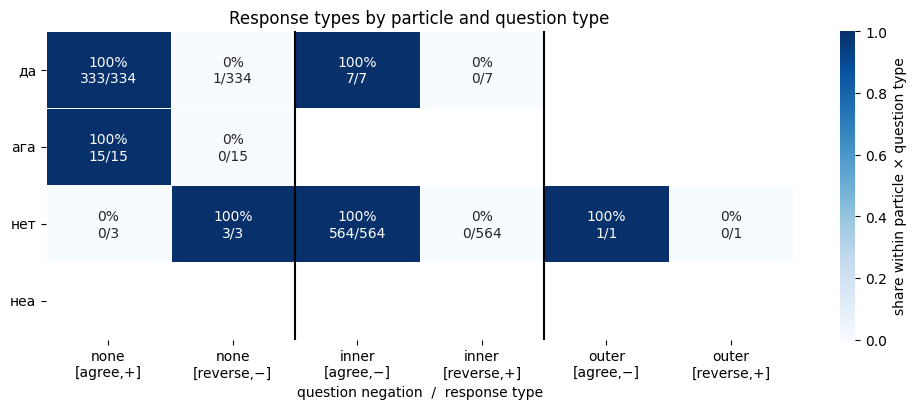

In [15]:
# within a negation type only two response types are possible, so show only those 6 columns
COLS = [('none', '[agree,+]'), ('none', '[reverse,−]'),
        ('inner', '[agree,−]'), ('inner', '[reverse,+]'),
        ('outer', '[agree,−]'), ('outer', '[reverse,+]')]

vals = np.full((len(PARTICLES), len(COLS)), np.nan)
labels = np.empty(vals.shape, dtype=object)
for i, p in enumerate(PARTICLES):
    for j, (nt, rt) in enumerate(COLS):
        k, n = tab.loc[(nt, p), rt], tab.loc[(nt, p), 'n']
        vals[i, j] = k / n if n else np.nan
        labels[i, j] = f'{k / n:.0%}\n{k}/{n}' if n else '—'

fig, ax = plt.subplots(figsize=(10, 4.2))
sns.heatmap(vals, annot=labels, fmt='', cmap='Blues', vmin=0, vmax=1,
            linewidths=0.5, linecolor='white', cbar_kws={'label': 'share within particle × question type'},
            xticklabels=[f'{nt}\n{rt}' for nt, rt in COLS], yticklabels=PARTICLES, ax=ax)
for x in (2, 4):
    ax.axvline(x, color='black', lw=1.5)
ax.set_xlabel('question negation  /  response type')
ax.set_ylabel('')
ax.tick_params(axis='y', rotation=0)
ax.set_title('Response types by particle and question type')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'heatmap_response_types.png'), dpi=200)
plt.show()






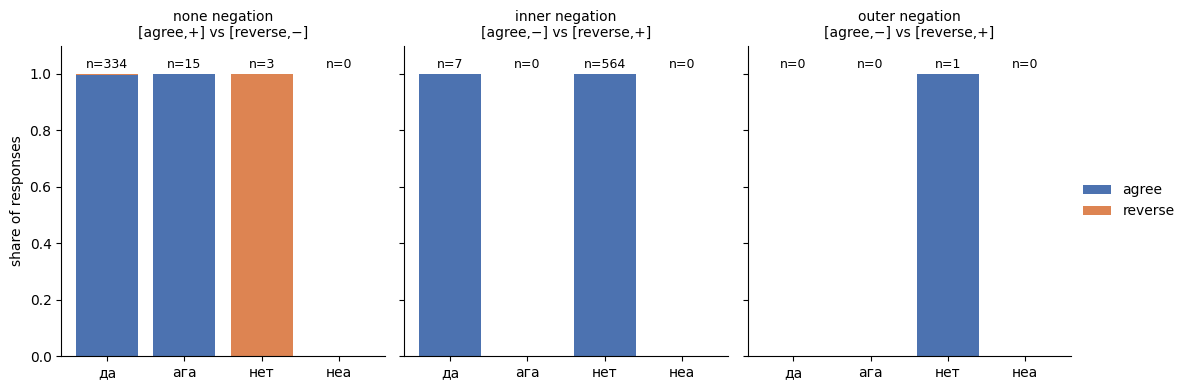

In [16]:
# stacked bars
REL_COLORS = {'agree': '#4C72B0', 'reverse': '#DD8452'}
PANEL_TYPES = {'none': ('[agree,+]', '[reverse,−]'),
               'inner': ('[agree,−]', '[reverse,+]'),
               'outer': ('[agree,−]', '[reverse,+]')}

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
for ax, nt in zip(axes, NEG_TYPES):
    a_t, r_t = PANEL_TYPES[nt]
    sub = prop.loc[nt]
    n = tab.loc[nt, 'n']
    x = np.arange(len(PARTICLES))
    ax.bar(x, sub[a_t].fillna(0), color=REL_COLORS['agree'], label='agree')
    ax.bar(x, sub[r_t].fillna(0), bottom=sub[a_t].fillna(0), color=REL_COLORS['reverse'], label='reverse')
    for xi, ni in zip(x, n):
        ax.text(xi, 1.02, f'n={ni}', ha='center', fontsize=9)
    ax.set_xticks(x, PARTICLES)
    ax.set_title(f'{nt} negation\n{a_t} vs {r_t}', fontsize=10)
    ax.set_ylim(0, 1.1)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('share of responses')
axes[-1].legend(frameon=False, loc='center left', bbox_to_anchor=(1.0, 0.5))
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'stacked_bars.png'), dpi=200)
plt.show()


***
## Step 4. Contextual embeddings.
* Extract ruBERT (DeepPavlov rubert-base-cased) embeddings of each particle token in its context.
* Group the tokens by particle × question type (positive question, inner negation, outer negation).
* Reduce dimensionality with PCA and visualize all groups on one plot.
* Cluster the embeddings with k-means and compare the clusters with the particle × question-type groups.

**Goal**: H4, i.e. check whether ruBERT represents the same particle differently depending on the type of question it answers.

In [17]:
Q_LABELS = {'none': 'positive question', 'inner': 'inner negation', 'outer': 'outer negation'}

emb = q.copy().reset_index(drop=True)
for col in ['Left context', 'Center', 'Punct', 'Right context']:
    emb[col] = emb[col].fillna('').astype(str)
emb['group'] = emb['particle'] + ' | ' + emb['neg_type'].map(Q_LABELS)
print('Tokens:', len(emb))
display(emb['group'].value_counts())

MODEL = 'DeepPavlov/rubert-base-cased'
device = 'cuda' if torch.cuda.is_available() else 'cpu'
tok = AutoTokenizer.from_pretrained(MODEL)
bert = AutoModel.from_pretrained(MODEL).to(device).eval()

def make_text(row, max_chars=300):
    """Return the text and the character span of the particle in it."""
    text = row['Left context'][-max_chars:].strip() + ' '
    start = len(text)
    text += row['Center']
    end = len(text)
    text += row['Punct'] + ' ' + row['Right context'][:max_chars]
    return text.strip(), start, end

@torch.no_grad()
def embed(df, batch_size=16):
    """Mean of the particle's sub-tokens, averaged over the last 4 layers."""
    vecs = []
    rows = [r for _, r in df.iterrows()]
    for i in range(0, len(rows), batch_size):
        items = [make_text(r) for r in rows[i:i + batch_size]]
        enc = tok([t for t, _, _ in items], return_offsets_mapping=True, truncation=True,
                  max_length=512, padding=True, return_tensors='pt')
        offsets = enc.pop('offset_mapping')
        hs = bert(**{k: v.to(device) for k, v in enc.items()}, output_hidden_states=True).hidden_states
        h = torch.stack(hs[-4:]).mean(0).cpu()
        for j, (_, s, t_end) in enumerate(items):
            off = offsets[j]
            mask = (off[:, 0] < t_end) & (off[:, 1] > s) & (off[:, 1] > off[:, 0])
            vecs.append(h[j][mask].mean(0).numpy())
    return np.vstack(vecs)

E = embed(emb)
np.save(os.path.join(WORK_DIR, 'step5_embeddings.npy'), E)
print(E.shape)

Tokens: 924


,count
group,
нет | inner negation,564
да | positive question,334
ага | positive question,15
да | inner negation,7
нет | positive question,3
нет | outer negation,1


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: DeepPavlov/rubert-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


(924, 768)


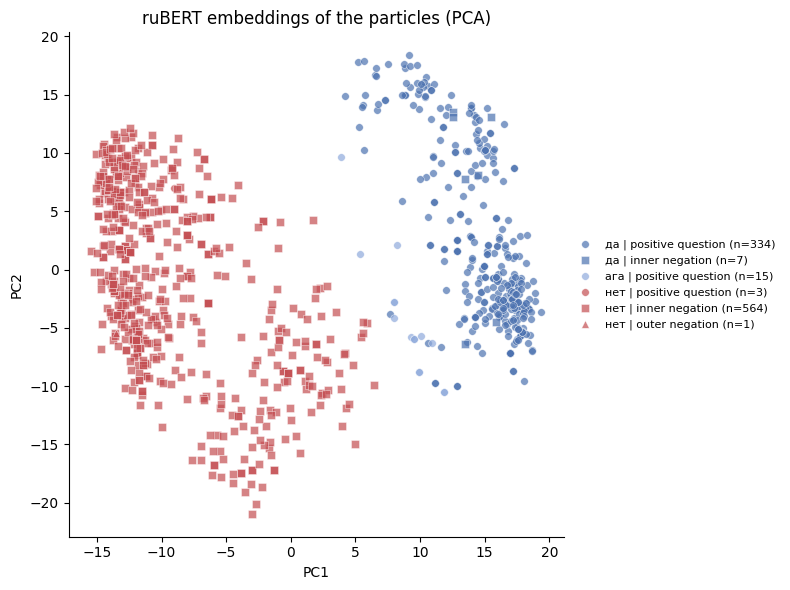

In [18]:
PARTICLE_COLORS = dict(zip(PARTICLES, ['#4C72B0', '#8FAADC', '#C44E52', '#E8A0A2']))
QTYPE_MARKERS = {'none': 'o', 'inner': 's', 'outer': '^'}

Z = PCA(n_components=2, random_state=0).fit_transform(StandardScaler().fit_transform(E))
emb['pc1'], emb['pc2'] = Z[:, 0], Z[:, 1]

fig, ax = plt.subplots(figsize=(8, 6))
for p in PARTICLES:
    for nt in QTYPE_MARKERS:
        s = emb[(emb['particle'] == p) & (emb['neg_type'] == nt)]
        if len(s):
            ax.scatter(s['pc1'], s['pc2'], c=PARTICLE_COLORS[p], marker=QTYPE_MARKERS[nt], s=30,
                       alpha=0.7, edgecolors='white', linewidths=0.4, label=f'{p} | {Q_LABELS[nt]} (n={len(s)})')
ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
ax.set_title('ruBERT embeddings of the particles (PCA)')
ax.legend(frameon=False, fontsize=8, bbox_to_anchor=(1.0, 0.5), loc='center left')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'step5_pca.png'), dpi=200)
plt.show()

k = 6
ARI, clusters vs particle × question type: 0.316
ARI, clusters vs particle:                0.318
ARI, clusters vs question type:           0.32


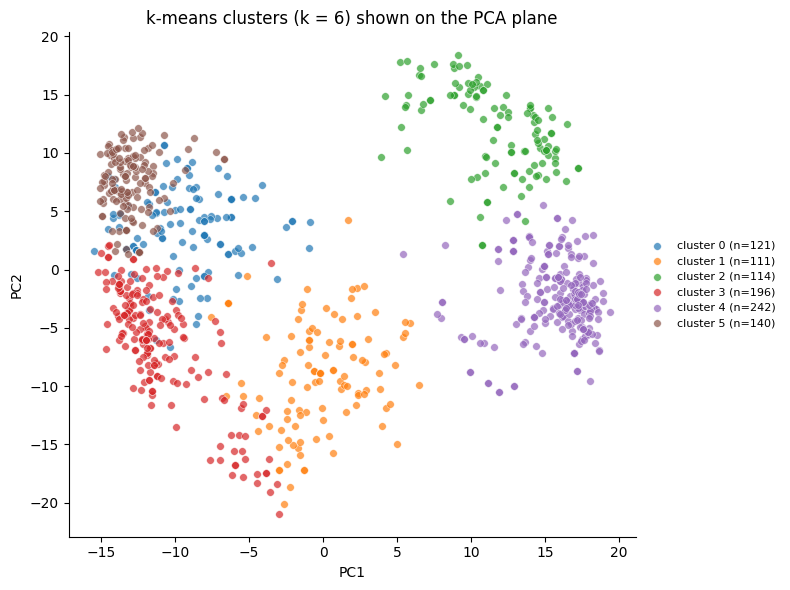

In [19]:
K = emb['group'].nunique()   # as many clusters as particle × question-type groups
X = PCA(n_components=min(50, len(E) - 1), random_state=0).fit_transform(StandardScaler().fit_transform(E))
emb['cluster'] = KMeans(n_clusters=K, n_init=10, random_state=0).fit_predict(X)

print('k =', K)
print('ARI, clusters vs particle × question type:', round(adjusted_rand_score(emb['group'], emb['cluster']), 3))
print('ARI, clusters vs particle:               ', round(adjusted_rand_score(emb['particle'], emb['cluster']), 3))
print('ARI, clusters vs question type:          ', round(adjusted_rand_score(emb['neg_type'], emb['cluster']), 3))

fig, ax = plt.subplots(figsize=(8, 6))
cmap = plt.get_cmap('tab10')
for c in sorted(emb['cluster'].unique()):
    s = emb[emb['cluster'] == c]
    ax.scatter(s['pc1'], s['pc2'], color=cmap(c % 10), s=30, alpha=0.7,
               edgecolors='white', linewidths=0.4, label=f'cluster {c} (n={len(s)})')
ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
ax.set_title(f'k-means clusters (k = {K}) shown on the PCA plane')
ax.legend(frameon=False, fontsize=8, bbox_to_anchor=(1.0, 0.5), loc='center left')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'step5_kmeans.png'), dpi=200)
plt.show()

PCA clearly separates *da* and *net*, while *aga* lies between them, closer to *da*. This suggests that *aga* may not behave exactly like *da*, although the LLM annotation did not distinguish them.

k-means finds two clusters among *da* and four among *net*. These clusters do not correspond to question types: almost all *da* tokens follow positive questions and almost all *net* tokens follow negative ones. For the same reason the three ARI values are nearly identical (≈0.32): in our data, particle and question type almost coincide, so the clustering cannot tell them apart.

# Conclusions
**H1** (*net* and *nea* behave alike): cannot be tested, since *nea* does not occur in the data.

**H2** (*da* has no [reverse,+] readings): supported. All [reverse,+] cases of *da* in the automatic annotation turned out to be errors.

**H3** (*aga* allows sarcastic [reverse,+]): not supported by the data. *aga* occurs only in [agree,+] answers, but with 15 examples a rare sarcastic use could easily be missed.

**H4** (language models reflect the distribution): partly supported. ruBERT clearly separates *da* and *net* and places *aga* close to *da*. Whether it also encodes the type of question cannot be determined, because particle and question type almost coincide in our data.

**Limitations**: the automatic annotation was validated on a very small sample and seems to overuse inner negation; the sample contains very few answers to negative questions.